In [38]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, AgglomerativeClustering, DBSCAN
from sklearn.mixture import GaussianMixture
from sklearn.metrics import silhouette_score
from scipy.cluster.hierarchy import dendrogram, linkage

df = pd.read_csv("Wine_clust.csv")
df.head()

,Alcohol,Malic_Acid,Ash,Ash_Alcanity,Magnesium,Total_Phenols,Flavanoids,Nonflavanoid_Phenols,Proanthocyanins,Color_Intensity,Hue,OD280,Proline
0,14.23,1.71,2.43,15.6,127,2.80,3.06,0.28,2.29,5.64,1.04,3.92,1065
1,13.20,1.78,2.14,11.2,100,2.65,2.76,0.26,1.28,4.38,1.05,3.40,1050
2,13.16,2.36,2.67,18.6,101,2.80,3.24,0.30,2.81,5.68,1.03,3.17,1185
3,14.37,1.95,2.50,16.8,113,3.85,3.49,0.24,2.18,7.80,0.86,3.45,1480
4,13.24,2.59,2.87,21.0,118,2.80,2.69,0.39,1.82,4.32,1.04,2.93,735


In [39]:
df.shape

(178, 13)

In [40]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 178 entries, 0 to 177
Data columns (total 13 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   Alcohol               178 non-null    float64
 1   Malic_Acid            178 non-null    float64
 2   Ash                   178 non-null    float64
 3   Ash_Alcanity          178 non-null    float64
 4   Magnesium             178 non-null    int64  
 5   Total_Phenols         178 non-null    float64
 6   Flavanoids            178 non-null    float64
 7   Nonflavanoid_Phenols  178 non-null    float64
 8   Proanthocyanins       178 non-null    float64
 9   Color_Intensity       178 non-null    float64
 10  Hue                   178 non-null    float64
 11  OD280                 178 non-null    float64
 12  Proline               178 non-null    int64  
dtypes: float64(11), int64(2)
memory usage: 18.2 KB


In [41]:
df.describe()

,Alcohol,Malic_Acid,Ash,Ash_Alcanity,Magnesium,Total_Phenols,Flavanoids,Nonflavanoid_Phenols,Proanthocyanins,Color_Intensity,Hue,OD280,Proline
count,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000
mean,13.000618,2.336348,2.366517,19.494944,99.741573,2.295112,2.029270,0.361854,1.590899,5.058090,0.957449,2.611685,746.893258
std,0.811827,1.117146,0.274344,3.339564,14.282484,0.625851,0.998859,0.124453,0.572359,2.318286,0.228572,0.709990,314.907474
min,11.030000,0.740000,1.360000,10.600000,70.000000,0.980000,0.340000,0.130000,0.410000,1.280000,0.480000,1.270000,278.000000
25%,12.362500,1.602500,2.210000,17.200000,88.000000,1.742500,1.205000,0.270000,1.250000,3.220000,0.782500,1.937500,500.500000
50%,13.050000,1.865000,2.360000,19.500000,98.000000,2.355000,2.135000,0.340000,1.555000,4.690000,0.965000,2.780000,673.500000
75%,13.677500,3.082500,2.557500,21.500000,107.000000,2.800000,2.875000,0.437500,1.950000,6.200000,1.120000,3.170000,985.000000
max,14.830000,5.800000,3.230000,30.000000,162.000000,3.880000,5.080000,0.660000,3.580000,13.000000,1.710000,4.000000,1680.000000


In [42]:
df.isnull().sum()

,0
Alcohol,0
Malic_Acid,0
Ash,0
Ash_Alcanity,0
Magnesium,0
Total_Phenols,0
Flavanoids,0
Nonflavanoid_Phenols,0
Proanthocyanins,0
Color_Intensity,0


In [43]:
X = StandardScaler().fit_transform(df)

In [44]:
from sklearn.decomposition import PCA
X_pca = PCA(n_components=2).fit_transform(X)

K-Means

In [45]:
scores = []
for k in range(2, 11):
    model = KMeans(n_clusters=k, random_state=42).fit(X)
    scores.append(silhouette_score(X, model.labels_))
    print(k, model.inertia_, scores[-1])

2 1661.6761165626497 0.2650328591008738
3 1277.928488844643 0.2848589191898987
4 1211.753113467159 0.25422758316007776
5 1123.1565470796968 0.18362105107698137
6 1079.5385091588266 0.16899191019013057
7 1014.4309086924653 0.1726015561094921
8 982.6549762937693 0.16250411307671142
9 927.9560760726207 0.1738739334545086
10 879.4257007542493 0.13956723664297546


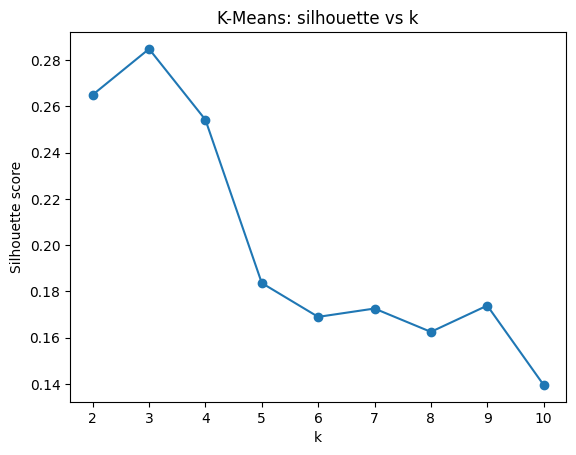

In [46]:
plt.plot(range(2, 11), scores, marker="o")
plt.xlabel("k"); plt.ylabel("Silhouette score")
plt.title("K-Means: silhouette vs k")
plt.show()

In [47]:
kmeans = KMeans(n_clusters=3, random_state=42).fit(X)
df["KMeans"] = kmeans.labels_
df["KMeans"].value_counts()

,count
KMeans,
0,65
2,62
1,51


Hierarchical clustering

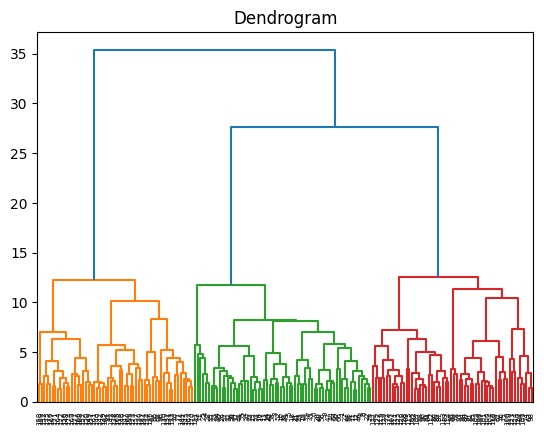

In [48]:
dendrogram(linkage(X, method="ward"))
plt.title("Dendrogram")
plt.show()

In [49]:
for k in range(2, 11):
    lab = AgglomerativeClustering(n_clusters=k).fit_predict(X)
    print(k, silhouette_score(X, lab))

2 0.2670131771272231
3 0.2774439826952265
4 0.225836659334758
5 0.18674235566758707
6 0.17966642854438503
7 0.18685342560226942
8 0.18834697102837825
9 0.1917169293227209
10 0.19856750165505588


In [50]:
hc = AgglomerativeClustering(n_clusters=3)
df["Hierarchical"] = hc.fit_predict(X)
df["Hierarchical"].value_counts()

,count
Hierarchical,
2,64
0,58
1,56


DBSCAN

In [51]:
db = DBSCAN(eps=2.3, min_samples=7)
df["DBSCAN"] = db.fit_predict(X)
df["DBSCAN"].value_counts()

,count
DBSCAN,
0,90
-1,52
1,36


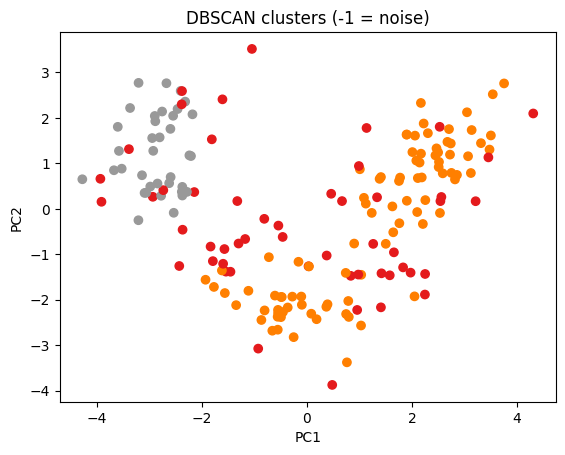

In [52]:
plt.scatter(X_pca[:, 0], X_pca[:, 1], c=df["DBSCAN"], cmap="Set1")
plt.title("DBSCAN clusters (-1 = noise)")
plt.xlabel("PC1"); plt.ylabel("PC2")
plt.show()

Gaussian Mixture

In [53]:
for k in range(2, 11):
    g = GaussianMixture(n_components=k, random_state=42).fit(X)
    print(k, g.bic(X))

2 5629.57338899323
3 5842.330291718671
4 5806.820273761148
5 6463.001990181156
6 6863.554404124685
7 6917.5471684860695
8 6407.919462920741
9 6448.655564129234
10 6645.619601401609


In [54]:
gmm = GaussianMixture(n_components=2, random_state=42).fit(X)
df["GMM"] = gmm.predict(X)
df["GMM"].value_counts()

,count
GMM,
0,122
1,56


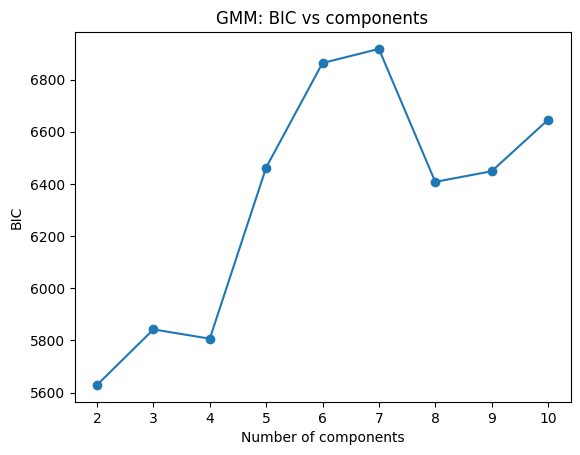

In [55]:
bic = []
for k in range(2, 11):
    bic.append(GaussianMixture(n_components=k, random_state=42).fit(X).bic(X))

plt.plot(range(2, 11), bic, marker="o")
plt.xlabel("Number of components"); plt.ylabel("BIC")
plt.title("GMM: BIC vs components")
plt.show()

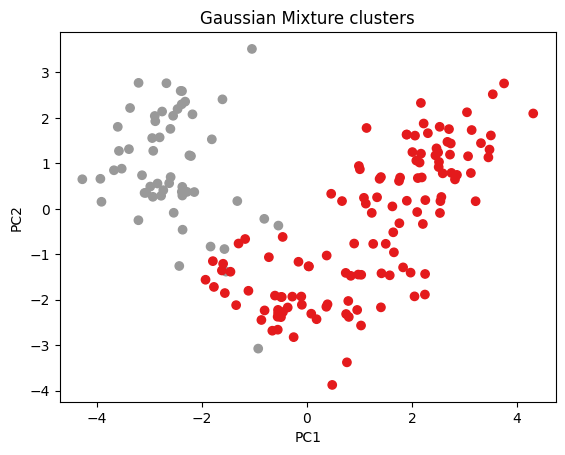

In [56]:
plt.scatter(X_pca[:, 0], X_pca[:, 1], c=df["GMM"], cmap="Set1")
plt.title("Gaussian Mixture clusters")
plt.xlabel("PC1"); plt.ylabel("PC2")
plt.show()

Final Output

In [57]:
df.head()

,Alcohol,Malic_Acid,Ash,Ash_Alcanity,Magnesium,Total_Phenols,Flavanoids,Nonflavanoid_Phenols,Proanthocyanins,Color_Intensity,Hue,OD280,Proline,KMeans,Hierarchical,DBSCAN,GMM
0,14.23,1.71,2.43,15.6,127,2.80,3.06,0.28,2.29,5.64,1.04,3.92,1065,2,2,0,0
1,13.20,1.78,2.14,11.2,100,2.65,2.76,0.26,1.28,4.38,1.05,3.40,1050,2,2,0,0
2,13.16,2.36,2.67,18.6,101,2.80,3.24,0.30,2.81,5.68,1.03,3.17,1185,2,2,0,0
3,14.37,1.95,2.50,16.8,113,3.85,3.49,0.24,2.18,7.80,0.86,3.45,1480,2,2,0,0
4,13.24,2.59,2.87,21.0,118,2.80,2.69,0.39,1.82,4.32,1.04,2.93,735,2,2,0,0
